# Adversarial Search: Playing "Mean" Connect 4


## Instructions

Total Points: Undegraduates 10, graduate students 11

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play "Mean" Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

> **The mean part:** This game has an additional rule. Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.

Note that normal [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

In [1]:
# Search problem for "Mean" Connect 4   (board values: 0 empty, 1 = Max/red, -1 = Min/yellow)
#
# State        : the board plus the player whose turn it is.
# Initial state: an empty rows x cols board, red (1) moves first.
# Actions(s)   : ("drop", col)      -> drop a new disc on top of column col
#                ("move", frm, to)  -> "mean" move: take the OPPONENT's disc from the bottom
#                                      row of column frm, let every disc above it fall one
#                                      row, and drop that disc into column to
# Transition   : result(s, a) -> new board (implemented in Task 2)
# Terminal(s)  : someone has `connect` discs in a line, or the board is full (draw),
#                or the position repeats (a draw in the search, see Task 3)
# Utility(s)   : +1 win, -1 loss, 0 draw, always seen from the player the agent plays

def drop(col):
    """action: drop a new disc into column col"""
    return ("drop", col)

def mean_move(frm, to):
    """action: steal the opponent's bottom disc of column frm and drop it into column to"""
    return ("move", frm, to)


**Giải thích các thành phần**

| Thành phần | Trong "Mean" Connect 4 |
|---|---|
| Trạng thái | bàn cờ `numpy` kích thước bất kỳ + người sắp đi; quân rơi xuống đáy nên cột luôn được lấp từ dưới lên |
| Trạng thái đầu | bàn cờ toàn 0, quân đỏ (1) đi trước |
| Hành động | `("drop", col)` hoặc `("move", from, to)` |
| Mô hình chuyển tiếp | `result(s, a)`: thêm quân, hoặc bốc quân đối thủ ở hàng đáy rồi thả lại vào cột khác (các quân phía trên tụt xuống một ô) |
| Kiểm tra kết thúc | có `connect` quân thẳng hàng, hoặc bàn cờ đầy (hòa), hoặc thế cờ lặp lại (hòa) |
| Hàm lợi ích | +1 thắng, −1 thua, 0 hòa, tính theo góc nhìn của người chơi được truyền vào agent |

Ba quyết định thiết kế đáng chú ý:

* **Nước "mean" là một bộ đôi cột** `(from, to)` chứ không phải một cột. Cột `from` phải có quân **đối thủ** ở hàng đáy, cột `to` phải còn chỗ.
* **Không cho `from == to`**: đặt quân trở lại đúng chỗ cũ là một nước "pass" vô nghĩa, chỉ làm action space phình ra gấp đôi.
* **Luật lặp lại**: nước mean không thêm quân, nên hai bên có thể hoán đổi quân qua lại mãi mãi. Vì vậy khi tìm kiếm, một thế cờ đã xuất hiện trong cùng nhánh được tính là hòa — nếu không, minimax không bao giờ kết thúc (xem Task 3).


How big is the state space? Give an estimate and explain it.

In [2]:
rows, cols = 6, 7

naive = 3 ** (rows * cols)
print(f"no gravity, every cell empty/red/yellow: 3^{rows * cols} = {naive:.2e}")

# with gravity a column of height h has 2^h colourings (bottom-up filling only)
per_column = sum(2 ** h for h in range(rows + 1))
bound = per_column ** cols
print(f"with gravity, one column has {per_column} fillings -> board <= {per_column}^{cols} = {bound:.2e}")

legal = 4.53e12          # Tromp's count of legal Connect 4 positions
print(f"legal positions (Tromp): {legal:.2e}; x2 for the side to move -> {2 * legal:.2e}")
print(f"the alternating turn rule cuts the gravity bound by a factor of {bound / legal:.1e}")


no gravity, every cell empty/red/yellow: 3^42 = 1.09e+20
with gravity, one column has 127 fillings -> board <= 127^7 = 5.33e+14
legal positions (Tromp): 4.53e+12; x2 for the side to move -> 9.06e+12
the alternating turn rule cuts the gravity bound by a factor of 1.2e+02


**Ước lượng không gian trạng thái**

* Nếu bỏ qua trọng lực: mỗi ô có 3 khả năng (trống / đỏ / vàng) → $3^{42} \approx 1.09 \times 10^{20}$.
* Có trọng lực, một cột cao $h$ chỉ có $2^h$ cách tô màu (lấp từ dưới lên) → một cột có $\sum_{h=0}^{6} 2^h = 127$ trạng thái, cả bàn $\le 127^7 \approx 5.33 \times 10^{14}$.
* Ràng buộc "hai bên đi luân phiên" cắt thêm khoảng 120 lần: số thế cờ hợp lệ của Connect 4 đã được đếm là $4.53 \times 10^{12}$ (Tromp), nhân 2 cho người sắp đi → $\approx 9.06 \times 10^{12}$.

Luật "mean" **không làm tăng** không gian trạng thái: nó chỉ bốc một quân ở hàng đáy rồi thả lại, trọng lực vẫn được giữ, nên tập bàn cờ vẫn là tập bàn cờ Connect 4 hợp lệ. Cái mà luật này thay đổi là **quan hệ chuyển tiếp và branching factor**, không phải số trạng thái.


How big is the game tree that minimax search will go through? Give an estimate and explain it.

In [3]:
drops = cols                     # one drop per column
mean_moves = cols * (cols - 1)   # from any column into any other column (upper bound)
branching = drops + mean_moves

print(f"max branching factor: {drops} drops + {mean_moves} mean moves = {branching}")
print(f"drop-only tree, 42 plies: {cols}^{42} = {cols ** 42:.2e} nodes")
print(f"full tree, 42 plies     : {branching}^{42} = {branching ** 42:.2e} nodes")
print("and a mean move adds no disc, so the tree is not even finite without a repetition rule")


max branching factor: 7 drops + 42 mean moves = 49
drop-only tree, 42 plies: 7^42 = 3.12e+35 nodes
full tree, 42 plies     : 49^42 = 9.73e+70 nodes
and a mean move adds no disc, so the tree is not even finite without a repetition rule


**Ước lượng cây trò chơi**

* Branching factor tối đa: 7 nước thả + $7 \times 6 = 42$ nước mean → **49**.
* Chỉ tính nước thả, sâu 42 ply (bàn đầy): $7^{42} \approx 3.12 \times 10^{35}$ node.
* Tính cả nước mean: $49^{42} \approx 9.73 \times 10^{70}$ node.

Con số thứ hai còn **đánh giá thấp** độ lớn thật, vì nước mean không thêm quân nên độ sâu không bị chặn bởi 42. Đây chính là lý do phải có luật lặp lại (hòa) trong phần tìm kiếm, và lý do minimax đầy đủ chỉ chạy được trên bàn rất nhỏ.


## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [4]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

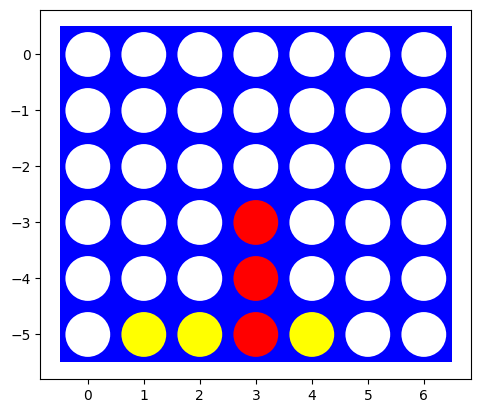

In [5]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

In [6]:
import contextlib
import numpy as np

CONNECT = 4          # discs in a line needed to win

def other(player):
    return -player

def new_board(rows=6, cols=7):
    """integer version of empty_board(): easier to print and to sum"""
    return empty_board((rows, cols)).astype(int)


def actions(state, player):
    """all legal actions: drops into non-full columns, plus the mean moves"""
    rows, cols = state.shape
    acts = [drop(c) for c in range(cols) if state[0, c] == 0]
    for frm in range(cols):
        if state[rows - 1, frm] == other(player):
            acts += [mean_move(frm, to) for to in range(cols)
                     if to != frm and state[0, to] == 0]
    return acts


def lowest_empty(state, col):
    """row of the lowest free cell of a column (the disc falls there)"""
    for r in range(state.shape[0] - 1, -1, -1):
        if state[r, col] == 0:
            return r
    raise ValueError(f"column {col} is full")


def apply_action(state, player, action, pieces=None):
    """transition model. Returns (new board, list of changed cells, number of discs)."""
    board = state.copy()
    if action[0] == "drop":
        r, c = lowest_empty(board, action[1]), action[1]
        board[r, c] = player
        changed = [(r, c)]
        pieces = None if pieces is None else pieces + 1
    else:
        _, frm, to = action
        if board[-1, frm] != other(player):
            raise ValueError(f"no {other(player)} disc at the bottom of column {frm}")
        if board[0, to] != 0:
            raise ValueError(f"column {to} is full")
        board[1:, frm] = board[:-1, frm]      # discs above fall one row down ...
        board[0, frm] = 0
        r = lowest_empty(board, to)
        board[r, to] = other(player)          # ... and the stolen disc is dropped again
        changed = [(r, to)] + [(r2, frm) for r2 in range(board.shape[0])]
    return board, changed, pieces


def result(state, player, action):
    """the new board only"""
    return apply_action(state, player, action)[0]


DIRECTIONS = ((0, 1), (1, 0), (1, 1), (1, -1))

def run_length(board, r, c, dr, dc, player):
    """length of the line of `player` discs through (r, c) in direction (dr, dc)"""
    n = 1
    for step in (1, -1):
        rr, cc = r + step * dr, c + step * dc
        while 0 <= rr < board.shape[0] and 0 <= cc < board.shape[1] and board[rr, cc] == player:
            n += 1
            rr += step * dr
            cc += step * dc
    return n


def wins_at(board, r, c, connect=None):
    """does the disc at (r, c) complete a line?"""
    connect = CONNECT if connect is None else connect
    player = board[r, c]
    if player == 0:
        return False
    return any(run_length(board, r, c, dr, dc, player) >= connect for dr, dc in DIRECTIONS)


def winner_of(board, changed, pieces, cells):
    """winner after one move, looking only at the changed cells (fast; used in the search)"""
    for r, c in changed:
        if wins_at(board, r, c):
            return int(board[r, c])
    return 0 if pieces == cells else None


def check_winner(board, connect=None):
    """whole board scan: 1 or -1 (winner), 0 (draw), None (game is not over)"""
    connect = CONNECT if connect is None else connect
    for r in range(board.shape[0]):
        for c in range(board.shape[1]):
            if board[r, c] != 0 and wins_at(board, r, c, connect):
                return int(board[r, c])
    return 0 if not (board == 0).any() else None


def terminal(state):
    """is the game over?"""
    return check_winner(state) is not None


def utility(state, player):
    """+1 win, -1 loss, 0 draw, seen from player; None for non-terminal states"""
    winner = check_winner(state)
    if winner is None:
        return None
    return 0 if winner == 0 else (1 if winner == player else -1)


@contextlib.contextmanager
def connect_rule(k):
    """temporarily change the winning rule (connect 3 is small enough for an exact search)"""
    global CONNECT
    old, CONNECT = CONNECT, k
    try:
        yield
    finally:
        CONNECT = old


# --- self checks ---------------------------------------------------------
b = new_board(4, 4)
for p, c in [(1, 0), (-1, 1), (1, 0), (-1, 2)]:
    b = result(b, p, drop(c))

moved = result(b, 1, mean_move(1, 3))
assert moved[3, 0] == 1 and moved[3, 1] == 0 and moved[3, 3] == -1, "discs must fall down"
assert terminal(moved) is False

line = new_board(4, 4)
line[3, :] = 1          # a full row of 4 wins with the standard rule
assert terminal(line) and utility(line, 1) == 1 and utility(line, -1) == -1

full = new_board(2, 2)
full[:] = [[1, -1], [-1, 1]]
assert utility(full, 1) == 0, "a full board without a line is a draw"

acts = actions(b, 1)
assert len(acts) == 10 and drop(0) in acts and mean_move(1, 3) in acts
print("all self checks passed")


all self checks passed


**Cách cài đặt**

* `actions` chỉ duyệt $O(\text{cols}^2)$ cột, không sinh nước đi rồi kiểm tra lại — cần thiết vì hàm này được gọi ở **mọi** node của cây tìm kiếm.
* `apply_action` trả về thêm danh sách **các ô thay đổi**. Nhờ vậy việc kiểm tra thắng chỉ cần nhìn quanh những ô đó (`winner_of`) thay vì quét lại cả bàn. Với nước mean, các ô của cột `from` cũng đổi (quân tụt xuống), nên chúng cũng nằm trong danh sách.
* `pieces` (số quân trên bàn) được truyền xuống để phát hiện hòa khi bàn đầy mà không phải đếm lại mảng.
* `check_winner` / `terminal` / `utility` là bản "chậm nhưng đơn giản" dùng ngoài vòng tìm kiếm (ví dụ trong `play`), còn trong search dùng bản tăng dần ở trên.
* `connect_rule(3)` cho phép tạm đổi luật thắng sang 3 quân để thí nghiệm trên bàn nhỏ; nó luôn khôi phục lại giá trị cũ kể cả khi có exception.
* Cuối cell là các `assert` tự kiểm tra: quân tụt đúng một ô khi bị bốc, thắng/thua/hòa tính đúng theo góc nhìn người chơi, số nước đi hợp lệ đúng.


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [7]:
import random

def random_player(board, player=None):
    """uniformly random legal action (player is only needed to know the mean moves)"""
    return random.choice(actions(board, 1 if player is None else player))

random.seed(42)     # makes the experiments reproducible
print("random action on an empty board:", random_player(new_board(), 1))


random action on an empty board: ('drop', 5)


Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [8]:
import time

def play(x, o, N=100, board=None, max_plies=200, verbose=False):
    """let x play red and o play yellow N times.
    Returns {1: red wins, -1: yellow wins, 0: draws} and, with verbose, all games."""
    results, games = {1: 0, -1: 0, 0: 0}, []
    for _ in range(N):
        b = new_board() if board is None else board.copy()
        pieces, player, moves = int(np.count_nonzero(b)), 1, []
        for _ in range(max_plies):
            a = (x if player == 1 else o)(b, player)
            if a not in actions(b, player):
                raise ValueError(f"agent returned an illegal action: {a}")
            moves.append((player, a))
            b, changed, pieces = apply_action(b, player, a, pieces)
            winner = winner_of(b, changed, pieces, b.size)
            if winner is not None:
                results[winner] += 1
                break
            player = -player
        else:
            results[0] += 1        # ply limit: count as a draw, the game can loop
        games.append(moves)
    return (results, games) if verbose else results


random.seed(0)
start = time.perf_counter()
res = play(random_player, random_player, N=1000)
print("results:", res)
total = sum(res.values())
for key, label in [(1, "red (first)"), (-1, "yellow"), (0, "draws")]:
    print(f"{label:>12}: {res[key]:4d} games ({res[key] / total:.1%})")
print(f"time: {time.perf_counter() - start:.1f} s")


results: {1: 773, -1: 227, 0: 0}
 red (first):  773 games (77.3%)
      yellow:  227 games (22.7%)
       draws:    0 games (0.0%)
time: 0.4 s


**Cách cài đặt environment**

* `play(x, o, N, board=None, max_plies=200)` nhận **hai agent function** cùng chữ ký `(board, player)`; agent không cần biết mình là màu nào, environment truyền `player` vào mỗi lượt.
* Mỗi nước đi được **kiểm tra hợp lệ** trước khi áp dụng (`if a not in actions(b, player): raise`). Vì agent có thể đến từ nơi khác (ví dụ ở phần tournament), đây là chốt kiểm soát bắt buộc chứ không phải kiểm tra thừa.
* Kết quả trả về là `{1: số ván đỏ thắng, -1: số ván vàng thắng, 0: số hòa}`.
* `max_plies` là **van an toàn**: nước mean không thêm quân nên hai agent có thể hoán đổi quân mãi mãi; vượt giới hạn thì tính hòa thay vì treo máy.
* `verbose=True` trả thêm danh sách nước đi của từng ván, dùng để vẽ lại thế cờ cuối ở Task 4.


**1000 ván random – random**

Kết quả: đỏ (đi trước) thắng **773** ván (77.3%), vàng thắng **227** ván (22.7%), **0** ván hòa.

Điều này *có thể dự đoán được* và cũng là điểm thú vị của luật mean: lợi thế đi trước bị **khuếch đại** so với Connect 4 thường (khoảng 55/45 khi chơi ngẫu nhiên). Lý do: người đi sau vừa đặt quân để đe dọa thì người đi trước có thể bốc chính quân đáy đó đi chỗ khác, phá luôn thế đe dọa, rồi lại có lượt tiếp theo. Nói cách khác, thế "tempo" đáng giá hơn hẳn.

Không có ván hòa nào trong 1000 ván: bàn 6×7 quá rộng để chơi ngẫu nhiên lấp đầy mà không ai tạo được 4 quân thẳng hàng.


## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

In [9]:
import math

class SearchTimeout(Exception):
    """raised when the search hits the time limit"""


def order_natural(board, player, acts):
    """no ordering: the drops (left to right) followed by the mean moves"""
    return acts


def make_order_center():
    """drops first, and inside each group the middle columns first"""
    def order(board, player, acts):
        centre = (board.shape[1] - 1) / 2
        key = lambda col: abs(col - centre)
        drops = sorted([a for a in acts if a[0] == "drop"], key=lambda a: key(a[1]))
        moves = sorted([a for a in acts if a[0] == "move"], key=lambda a: (key(a[2]), key(a[1])))
        return drops + moves
    return order


def make_order_winning():
    """immediate wins first, everything else in centre-first order"""
    center_order = make_order_center()

    def order(board, player, acts):
        wins, rest = [], []
        for a in acts:
            child, changed, _ = apply_action(board, player, a)
            if any(child[r, c] == player and wins_at(child, r, c) for r, c in changed):
                wins.append(a)
            else:
                rest.append(a)
        return wins + center_order(board, player, rest)
    return order


def alpha_beta_search(state, player, depth=None, heuristic=None, order=None,
                      time_limit=None, repetition=True, nodes=None):
    """minimax with alpha-beta pruning.

    depth=None          search until the game ends
    heuristic=fn        value in [-1, 1] used when depth runs out
    order=fn            move ordering; this changes speed, not the result
    repetition=True     a board that occurred earlier in the same line counts as a draw,
                        which is what keeps "mean" Connect 4 finite
    """
    root = player
    pieces = int(np.count_nonzero(state))
    deadline = None if time_limit is None else time.perf_counter() + time_limit
    counter = {"nodes": 0, "cutoffs": 0} if nodes is None else nodes
    order = order or order_natural
    limit = math.inf if depth is None else depth
    path = {state.tobytes()} if repetition else set()

    def leaf_value(board, depth_left):
        if depth_left == 0:                  # search cut off: use the heuristic
            return 0 if heuristic is None else heuristic(board, root)
        return None

    def max_value(board, pl, alpha, beta, depth_left, pieces, changed):
        counter["nodes"] += 1
        if deadline and counter["nodes"] % 1024 == 0 and time.perf_counter() > deadline:
            raise SearchTimeout
        winner = winner_of(board, changed, pieces, board.size)
        if winner is not None:
            return (0 if winner == 0 else (1 if winner == root else -1)), None
        value = leaf_value(board, depth_left)
        if value is not None:
            return value, None
        value, move = -math.inf, None
        for a in order(board, pl, actions(board, pl)):
            child, changed2, pieces2 = apply_action(board, pl, a, pieces)
            key = child.tobytes()
            if key in path:                  # position already seen in this line: a draw
                child_value = 0
            else:
                path.add(key)
                child_value, _ = min_value(child, -pl, alpha, beta, depth_left - 1, pieces2, changed2)
                path.discard(key)
            if child_value > value:
                value, move = child_value, a
            alpha = max(alpha, value)
            if value >= beta:
                counter["cutoffs"] += 1
                break
        return value, move

    def min_value(board, pl, alpha, beta, depth_left, pieces, changed):
        counter["nodes"] += 1
        if deadline and counter["nodes"] % 1024 == 0 and time.perf_counter() > deadline:
            raise SearchTimeout
        winner = winner_of(board, changed, pieces, board.size)
        if winner is not None:
            return (0 if winner == 0 else (1 if winner == root else -1)), None
        value = leaf_value(board, depth_left)
        if value is not None:
            return value, None
        value, move = math.inf, None
        for a in order(board, pl, actions(board, pl)):
            child, changed2, pieces2 = apply_action(board, pl, a, pieces)
            key = child.tobytes()
            if key in path:
                child_value = 0
            else:
                path.add(key)
                child_value, _ = max_value(child, -pl, alpha, beta, depth_left - 1, pieces2, changed2)
                path.discard(key)
            if child_value < value:
                value, move = child_value, a
            beta = min(beta, value)
            if value <= alpha:
                counter["cutoffs"] += 1
                break
        return value, move

    start = time.perf_counter()
    value, move = max_value(state, player, -math.inf, math.inf, limit, pieces, [])
    return {"move": move, "value": value, "nodes": counter["nodes"],
            "cutoffs": counter["cutoffs"], "time": time.perf_counter() - start}


WIN_FIRST = make_order_winning()     # the default ordering used by the agents

def alpha_beta_player(board, player=1):
    """exact alpha-beta agent"""
    return alpha_beta_search(board, player, order=WIN_FIRST)["move"]


**Cách cài đặt alpha-beta**

* Hai hàm `max_value` / `min_value` đệ quy chuẩn của minimax; `alpha`/`beta` được cập nhật sau mỗi nước và cắt nhánh khi `value >= beta` (max) hoặc `value <= alpha` (min).
* **Kiểm tra kết thúc tăng dần**: sau một nước chỉ những ô trong `changed` mới có thể tạo thành hàng, nên `winner_of` chỉ nhìn các ô đó thay vì quét cả bàn. Với nước mean, `changed` gồm cả cột bị bốc vì các quân phía trên vừa tụt xuống.
* **Luật lặp lại**: `path` giữ hash (`tobytes()`) của các thế cờ trên nhánh hiện tại; gặp lại thì trả 0 (hòa). Đây là thứ khiến bài toán hữu hạn và là lý do cell này chạy được trên bàn 4×4.
* `depth=None` tìm tới khi ván cờ kết thúc; `depth=k` cắt ở ply thứ `k` và trả `heuristic(board, root)` — dùng lại cùng một hàm cho Task 4 thay vì viết bản thứ hai.
* `order` là **tham số**, không phải nhánh code riêng: đổi thứ tự duyệt chỉ đổi tốc độ, không đổi value (đã kiểm chứng ở bảng Move ordering).
* `time_limit`: cứ 1024 node kiểm tra đồng hồ một lần và ném `SearchTimeout`, để thí nghiệm ghi "timeout" thay vì treo. Đếm `nodes`/`cutoffs` để so sánh các chiến lược.
* Hàm trả `{"move", "value", "nodes", "cutoffs", "time"}` để phần thí nghiệm in bảng trực tiếp.


Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

B1: red wins with one drop   (player 1 to move)


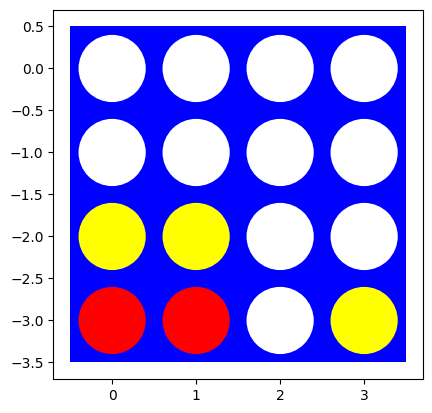

   move = ('drop', 2), value = 1, nodes = 151, time = 0.005 s

B2: red must block yellow   (player 1 to move)


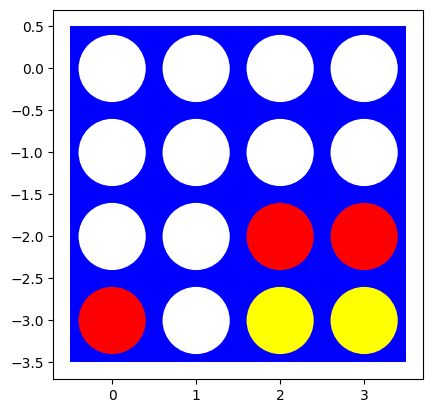

   move = ('drop', 1), value = 1, nodes = 1589, time = 0.043 s

B3: red wins with a mean move   (player 1 to move)


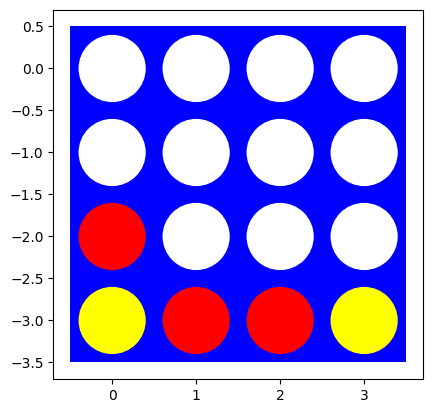

   move = ('move', 0, 1), value = 1, nodes = 262, time = 0.006 s

B4: B1 with yellow to move   (player -1 to move)


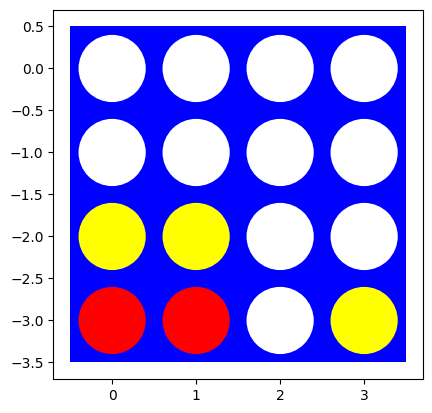

   move = ('drop', 2), value = 1, nodes = 1527, time = 0.038 s

B5: quiet board, no tactic   (player 1 to move)


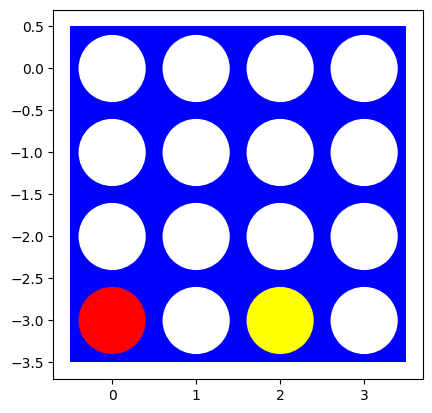

   move = ('drop', 0), value = 1, nodes = 7626, time = 0.196 s



In [10]:
def board_from_rows(*rows):
    """build a board from rows given top row first (same order as the printed board)"""
    b = new_board(len(rows), len(rows[0]))
    b[:] = rows
    return b


test_boards = {
    "B1: red wins with one drop":        (board_from_rows([0, 0, 0, 0], [0, 0, 0, 0],
                                                          [-1, -1, 0, 0], [1, 1, 0, -1]), 1),
    "B2: red must block yellow":         (board_from_rows([0, 0, 0, 0], [0, 0, 0, 0],
                                                          [0, 0, 1, 1], [1, 0, -1, -1]), 1),
    "B3: red wins with a mean move":     (board_from_rows([0, 0, 0, 0], [0, 0, 0, 0],
                                                          [1, 0, 0, 0], [-1, 1, 1, -1]), 1),
    "B4: B1 with yellow to move":        (board_from_rows([0, 0, 0, 0], [0, 0, 0, 0],
                                                          [-1, -1, 0, 0], [1, 1, 0, -1]), -1),
    "B5: quiet board, no tactic":        (board_from_rows([0, 0, 0, 0], [0, 0, 0, 0],
                                                          [0, 0, 0, 0], [1, 0, -1, 0]), 1),
}

exact = {}
with connect_rule(3):                      # connect 3 on 4x4 is small enough for a full search
    for name, (board, player) in test_boards.items():
        print(f"{name}   (player {player} to move)")
        visualize(board)
        r = alpha_beta_search(board, player, order=WIN_FIRST)
        exact[name] = r
        print(f"   move = {r['move']}, value = {r['value']}, nodes = {r['nodes']}, time = {r['time']:.3f} s\n")


**5 thế cờ thủ công** (bàn 4×4, luật connect 3 cho tìm kiếm được đầy đủ)

| Thế cờ | Nước đi của agent | Value | Node | Thời gian |
|---|---|---|---|---|
| B1: đỏ thắng bằng một nước thả | `drop 2` | +1 | 151 | 0.005 s |
| B2: đỏ phải chặn vàng | `drop 1` | +1 | 1 589 | 0.043 s |
| B3: đỏ thắng bằng nước mean | `move 0 -> 1` | +1 | 262 | 0.006 s |
| B4: B1 nhưng vàng đi | `drop 2` | +1 | 1 527 | 0.038 s |
| B5: thế cờ "yên", không có tactic | `drop 0` | +1 | 7 626 | 0.196 s |

* **B1**: agent thấy ngay nước thả hoàn tất hàng đáy.
* **B2**: vàng đe dọa hoàn tất hàng đáy ở cột 1; agent chặn đúng cột đó (và thực ra thế cờ này đỏ vẫn thắng).
* **B3**: đây là nước **mean** đẹp nhất. Đỏ bốc quân vàng ở đáy cột 0, quân đỏ phía trên tụt xuống hàng đáy và hoàn tất hàng 3 quân. Không có nước thả nào thắng được, nên đây là bằng chứng agent thật sự dùng luật mean.
* **B4**: cùng bàn với B1 nhưng `player = -1`; agent chặn nước thắng của đỏ (ô đáy cột 2) và thắng ngược. Điều này kiểm tra việc agent dùng đúng `player` chứ không hard-code màu đỏ.
* **B5**: bàn gần trống nhưng tìm kiếm đầy đủ vẫn cho value +1, tức đỏ thắng với 4×4 connect 3. Đây là lý do khi chơi 10 ván ở Task 3, agent thua khi cầm vàng.


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [11]:
def timed_search(board, player=1, **kw):
    """alpha-beta search; the result is None if the time limit was hit"""
    start = time.perf_counter()
    try:
        return alpha_beta_search(board, player, **kw), time.perf_counter() - start
    except SearchTimeout:
        return None, time.perf_counter() - start


with connect_rule(3):
    print("full alpha-beta search, connect 3, 4 rows, empty board, 10 s limit")
    print(f"{'columns':>7} {'nodes':>9} {'time [s]':>9}   move")
    for cols in (4, 5, 6, 7):
        r, dt = timed_search(new_board(4, cols), 1, order=WIN_FIRST, time_limit=10)
        if r is None:
            print(f"{cols:>7} {'-':>9} {'> 10':>9}   timeout")
        else:
            print(f"{cols:>7} {r['nodes']:>9} {dt:>9.2f}   {r['move']}")

r, dt = timed_search(new_board(6, 7), 1, order=WIN_FIRST, time_limit=10)
print("standard 6x7 board, connect 4, 10 s limit:",
      "timeout" if r is None else f"{r['nodes']} nodes, {dt:.2f} s, {r['move']}")


full alpha-beta search, connect 3, 4 rows, empty board, 10 s limit
columns     nodes  time [s]   move


      4     16651      0.41   ('drop', 1)


      5     67270      2.14   ('drop', 2)


      6         -      > 10   timeout


      7         -      > 10   timeout


standard 6x7 board, connect 4, 10 s limit: timeout


**Thời gian cho một nước đi (tìm kiếm đầy đủ, connect 3, 4 hàng)**

| Số cột | Node | Thời gian | Ghi chú |
|---|---|---|---|
| 4 | 16 651 | 0.41 s | |
| 5 | 67 270 | 2.14 s | |
| 6 | — | > 10 s | timeout |
| 7 | — | > 10 s | timeout |
| 6×7, connect 4 | — | > 10 s | timeout |

Mỗi cột thêm vào làm branching tăng thêm 1 nước thả **và** thêm $2 \times (\text{số cột})$ nước mean, nên thời gian tăng nhanh hơn nhiều so với hàm mũ cơ số 7. Bàn chuẩn 6×7 với luật 4 quân là bất khả thi với tìm kiếm đầy đủ — đúng như gợi ý của đề bài; vì vậy các thí nghiệm sau dùng bàn nhỏ, luật connect 3, hoặc cắt độ sâu.


### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [12]:
orders = {
    "no ordering":          order_natural,
    "centre first":         make_order_center(),
    "winning moves first":  make_order_winning(),
}

order_boards = {
    "empty 4x4":  new_board(4, 4),
    "B3":         test_boards["B3: red wins with a mean move"][0],
    "B5":         test_boards["B5: quiet board, no tactic"][0],
}

with connect_rule(3):
    print(f"{'board':<10} {'ordering':<22} {'nodes':>8} {'time [s]':>9}")
    for board_name, board in order_boards.items():
        for order_name, order in orders.items():
            r = alpha_beta_search(board, 1, order=order)
            print(f"{board_name:<10} {order_name:<22} {r['nodes']:>8} {r['time']:>9.3f}")


board      ordering                  nodes  time [s]


empty 4x4  no ordering              873253     5.530


empty 4x4  centre first             228770     1.700


empty 4x4  winning moves first       16651     0.414
B3         no ordering                 523     0.005
B3         centre first               1033     0.008
B3         winning moves first         262     0.006


B5         no ordering               66368     0.421


B5         centre first             131888     0.963
B5         winning moves first        7626     0.195


**Move ordering**

Ba chiến lược (chỉ đổi **thứ tự duyệt**, không đổi kết quả):

1. `no ordering`: thả trái → phải, rồi đến các nước mean.
2. `centre first`: thả trước, trong mỗi nhóm thì cột giữa trước.
3. `winning moves first`: nước thắng ngay lên đầu, phần còn lại theo centre-first.

| Bàn | Không sắp xếp | Centre first | Winning first |
|---|---|---|---|
| 4×4 trống | 873 253 node / 5.53 s | 228 770 / 1.70 s | **16 651 / 0.414 s** |
| B3 | 523 / 0.005 s | 1 033 / 0.008 s | **262 / 0.006 s** |
| B5 | 66 368 / 0.421 s | 131 888 / 0.963 s | **7 626 / 0.195 s** |

* Trên bàn trống 4×4, `winning moves first` giảm **52 lần** số node (873k → 16.6k) và **13 lần** thời gian: alpha-beta cắt tỉa tốt hơn nhiều khi nước tốt được duyệt trước.
* `centre first` **không phải lúc nào cũng nhanh hơn**: ở B3 và B5 nó còn chậm hơn không sắp xếp, vì trên bàn 4 cột thì "cột giữa" không còn nhiều ý nghĩa và thứ tự mới lại đẩy nước thắng ra sau.
* Cả ba chiến lược cho **cùng một value** (kiểm chứng: B3 luôn +1, B5 luôn +1) — đúng như yêu cầu, ordering chỉ ảnh hưởng tốc độ.
* Nhưng cùng value **không có nghĩa là cùng nước đi**: ở B3, `no ordering` và `centre first` chọn `drop 0` / `drop 1` (thắng nhưng chậm hơn), còn `winning moves first` chọn ngay nước mean thắng tức thì. Đây là lý do thứ hai để ưu tiên nước thắng khi sắp xếp.


### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [13]:
with connect_rule(3):
    board = new_board(4, 4)

    r, dt = timed_search(board, 1, order=order_natural)
    print(f"plain alpha-beta      : {r['nodes']:>6} nodes, {dt:.2f} s, move {r['move']}")

    r, dt = timed_search(board, 1, order=WIN_FIRST)
    print(f"winning moves first   : {r['nodes']:>6} nodes, {dt:.2f} s, move {r['move']}")

    print(f"opening book          :      0 nodes, 0.00 s, move {drop((board.shape[1] - 1) // 2)}")
    print("cut the search off at a fixed depth (measured in Task 4, cell for the width table)")


plain alpha-beta      : 873253 nodes, 5.47 s, move ('drop', 0)


winning moves first   :  16651 nodes, 0.41 s, move ('drop', 1)
opening book          :      0 nodes, 0.00 s, move ('drop', 1)
cut the search off at a fixed depth (measured in Task 4, cell for the width table)


**Nước đi đầu tiên trên bàn trống**

Bàn trống 4×4 (connect 3) là trường hợp xấu nhất: không có gì để cắt tỉa, phải giải gần như toàn bộ cây.

| Cách làm | Node | Thời gian |
|---|---|---|
| alpha-beta, không sắp xếp | 873 253 | 5.47 s |
| alpha-beta, `winning moves first` | 16 651 | 0.41 s |
| **opening book**: luôn thả cột giữa | 0 | 0.00 s |
| cắt ở độ sâu 4 + heuristic (Task 4) | 453 | 0.038 s |

Ba cách xử lý, tăng dần mức "đánh đổi độ chính xác":

1. **Move ordering** — rẻ nhất, không mất gì về chất lượng, đã giảm 13 lần thời gian.
2. **Opening book** — tìm kiếm đầy đủ cho value = +1 (đỏ thắng) và nhiều nước thả đều thắng, nên có thể "học thuộc" một nước đầu tốt (cột giữa) và trả lời tức thì. Cách này chỉ hợp lệ khi đã biết trước kết quả, đúng với bàn 4×4 connect 3.
3. **Cắt độ sâu + heuristic** — tổng quát nhất, dùng được cho 6×7, nhưng đánh đổi độ chính xác (xem Task 4, chỗ thế cờ B5 bị chọn sai nước).


### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [14]:
with connect_rule(3):
    small = new_board(4, 4)

    random.seed(0)
    start = time.perf_counter()
    res = play(alpha_beta_player, random_player, N=10, board=small)
    print(f"alpha-beta (red) vs random (yellow): {res}, {time.perf_counter() - start:.1f} s")

    random.seed(1)
    start = time.perf_counter()
    res = play(random_player, alpha_beta_player, N=10, board=small)
    print(f"random (red) vs alpha-beta (yellow): {res}, {time.perf_counter() - start:.1f} s")


alpha-beta (red) vs random (yellow): {1: 10, -1: 0, 0: 0}, 7.9 s


random (red) vs alpha-beta (yellow): {1: 3, -1: 7, 0: 0}, 4.9 s


**Playtime: alpha-beta đầy đủ vs random (4×4, connect 3, 10 ván mỗi chiều)**

| Vai trò của agent | Thắng | Thua | Hòa | Thời gian |
|---|---|---|---|---|
| Đỏ (đi trước) | **10** | 0 | 0 | 7.9 s |
| Vàng (đi sau) | **7** | 3 | 0 | 4.9 s |

* Cầm đỏ, agent thắng tuyệt đối: nó là search đầy đủ nên không bao giờ bỏ lỡ nước thắng/thua trong tầm với.
* Cầm vàng, agent **thua 3 ván dù chơi tối ưu**. Đây không phải lỗi: ở 4×4 connect 3 với luật mean, người đi trước có thế thắng cưỡng bức (value khởi đầu = +1). Khi đối thủ random tình cờ đi đúng, vàng không thể cứu. Việc agent thắng 7/10 còn lại cho thấy đỏ random thường không tìm ra đường thắng đó.
* Thời gian mỗi ván thấp hơn nhiều so với bàn trống vì càng về cuối cây càng nhỏ; 10 ván chỉ mất vài giây.


## Task 4: Heuristic Alpha-Beta Tree Search [3 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [15]:
from functools import lru_cache


@lru_cache(maxsize=None)
def windows(rows, cols, connect):
    """all lines of `connect` cells on a rows x cols board"""
    lines = []
    for r in range(rows):
        for c in range(cols):
            for dr, dc in DIRECTIONS:
                cells = tuple((r + i * dr, c + i * dc) for i in range(connect))
                if all(0 <= rr < rows and 0 <= cc < cols for rr, cc in cells):
                    lines.append(cells)
    return tuple(lines)


def heuristic(board, player):
    """static value of a position in (-1, 1), seen from player.

    A line that still can be completed is worth (number of own discs)^2, a line that
    already contains an opponent disc is worth nothing. A small term rewards the centre.
    tanh keeps the value inside (-1, 1) so it stays comparable to a win/loss value.
    """
    rows, cols = board.shape
    score = 0.0
    for cells in windows(rows, cols, CONNECT):
        mine = sum(1 for r, c in cells if board[r, c] == player)
        theirs = sum(1 for r, c in cells if board[r, c] == -player)
        if mine and theirs:
            continue                      # blocked line
        score += mine * mine - theirs * theirs

    centre = (cols - 1) / 2
    for r in range(rows):
        for c in range(cols):
            if board[r, c] == player:
                score += (cols - abs(c - centre)) / (4 * rows * cols)
            elif board[r, c] == -player:
                score -= (cols - abs(c - centre)) / (4 * rows * cols)

    return math.tanh(score / 10)


for name, (board, player) in test_boards.items():
    with connect_rule(3):
        v = heuristic(board, player)
    assert -1 < v < 1, "the heuristic must stay inside the range of a utility value"
    print(f"{name:<38} heuristic = {v:+.2f}")


B1: red wins with one drop             heuristic = -0.61
B2: red must block yellow              heuristic = +0.61
B3: red wins with a mean move          heuristic = +0.39
B4: B1 with yellow to move             heuristic = +0.61
B5: quiet board, no tactic             heuristic = -0.10


**Hàm heuristic**

$$h(s) = \tanh\!\Big(\frac{1}{10}\big(\sum_{\text{line}} \big(m^2 - o^2\big) + \text{centre bonus}\big)\Big)$$

* Với mỗi "line" (4 ô thẳng hàng, mọi hướng): nếu line còn **hoàn toàn trống hoặc chỉ có quân của mình** thì cộng $m^2$ ($m$ = số quân mình); nếu chỉ có quân đối thủ thì trừ $o^2$; nếu lẫn cả hai thì line bị chặn, giá trị 0.
* Bình phương để line 2 quân ($4$) đáng hơn hai line 1 quân ($2$), còn line 3 quân ($9$) gần như thắng.
* Cộng thêm một bonus nhỏ cho việc kiểm soát cột giữa.
* `tanh` ép giá trị vào $(-1, 1)$ — đúng khoảng của utility, để `alpha-beta` có thể trộn giá trị heuristic với giá trị thắng/thua mà không phá thứ tự.

Giá trị trên 5 thế cờ thủ công: B1 −0.61, B2 +0.61, B3 +0.39, B4 +0.61, B5 −0.10.

Chú ý **B1 bị điểm âm dù đỏ thắng ngay**: heuristic tĩnh chỉ đếm quân và line, mà ở B1 vàng có 4 quân so với 2 quân của đỏ. Việc "thấy" nước thắng 1 ply là nhiệm vụ của **search**, không phải của hàm đánh giá — và đúng là ở độ sâu ≥ 1 agent chọn đúng `drop 2`. Đây là ví dụ rõ cho việc heuristic và search bổ sung cho nhau.


### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

empty 6x7 board, connect 4
depth   nodes  time [s]  value   move
    1       8     0.001   0.61   ('drop', 3)
    2      30     0.002  -0.29   ('drop', 3)
    3     150     0.013   0.76   ('drop', 2)
    4     453     0.037  -0.20   ('drop', 3)


    5    3566     0.297   0.80   ('drop', 2)


    6    7191     0.614  -0.20   ('drop', 3)

mid-game 6x7 position


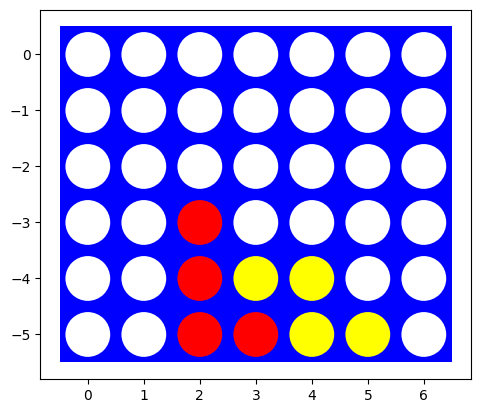

depth   nodes  time [s]  value   move
    1      20     0.002   1.00   ('drop', 2)
    2      38     0.003   1.00   ('drop', 2)
    3     342     0.031   1.00   ('drop', 2)
    4     627     0.056   1.00   ('drop', 2)


    5    3689     0.303   1.00   ('drop', 2)


    6    6326     0.506   1.00   ('drop', 2)


In [16]:
def depth_table(board, player=1, depths=range(1, 7)):
    print(f"{'depth':>5} {'nodes':>7} {'time [s]':>9} {'value':>6}   move")
    for depth in depths:
        r, dt = timed_search(board, player, depth=depth, heuristic=heuristic, order=WIN_FIRST)
        print(f"{depth:>5} {r['nodes']:>7} {dt:>9.3f} {r['value']:>6.2f}   {r['move']}")


print("empty 6x7 board, connect 4")
depth_table(new_board())

# a mid-game position, built from a fixed sequence of drops so that it is legal
random.seed(11)
mid = new_board()
for player, col in [(1, 3), (-1, 3), (1, 2), (-1, 4), (1, 2), (-1, 4), (1, 2), (-1, 5)]:
    mid = result(mid, player, drop(col))
assert terminal(mid) is False
print("\nmid-game 6x7 position")
visualize(mid)
depth_table(mid)


**Cắt độ sâu trên bàn chuẩn 6×7**

| Depth | Node | Thời gian | Value | Nước đi |
|---|---|---|---|---|
| 1 | 8 | 0.001 s | +0.61 | drop 3 |
| 2 | 30 | 0.002 s | −0.29 | drop 3 |
| 3 | 150 | 0.013 s | +0.76 | drop 2 |
| 4 | 453 | 0.037 s | −0.20 | drop 3 |
| 5 | 3 566 | 0.297 s | +0.80 | drop 2 |
| 6 | 7 191 | 0.614 s | −0.20 | drop 3 |

* Số node tăng khoảng 5–8 lần mỗi ply (nhỏ hơn branching 49 rất nhiều nhờ alpha-beta + move ordering).
* Value **dao động theo tính chẵn lẻ** của độ sâu (+0.61 / −0.29 / +0.76 / −0.20 …). Đây là hiệu ứng chân trời (horizon effect) cổ điển: ở depth lẻ, lượt cuối là của mình nên heuristic thấy "vừa đi thêm một nước"; ở depth chẵn thì ngược lại. Vì vậy đừng so sánh value giữa các depth khác parity — chỉ nên so trong cùng parity.
* Trên thế cờ giữa ván (8 quân), value = +1.00 ngay từ depth 1 vì đỏ đã có nước thắng cưỡng bức.



**Cài đặt:** phần cắt độ sâu không phải bản search mới — cùng hàm `alpha_beta_search` với `depth=k`, và tại node lá `leaf_value` trả `heuristic(board, root)` thay vì tiếp tục đệ quy. Nhờ vậy Task 3 và Task 4 dùng chung một bộ máy tìm kiếm, chỉ khác tham số.


Experiment with the same manually created boards as above to check if the agent spots winning opportunities.

In [17]:
with connect_rule(3):
    print(f"{'board':<38} {'exact':<13} {'depth 2':<13} {'depth 3':<13} {'depth 4':<13}")
    for name, (board, player) in test_boards.items():
        moves = [str(exact[name]["move"])]
        for depth in (2, 3, 4):
            r = alpha_beta_search(board, player, depth=depth, heuristic=heuristic, order=WIN_FIRST)
            moves.append(str(r["move"]))
        print(f"{name:<38} {moves[0]:<13} {moves[1]:<13} {moves[2]:<13} {moves[3]:<13}")

r, dt = timed_search(new_board(), 1, depth=3, heuristic=heuristic, order=WIN_FIRST)
print(f"depth 3 on the 6x7 board: {r['nodes']:>5} nodes, {dt:.3f} s")


board                                  exact         depth 2       depth 3       depth 4      
B1: red wins with one drop             ('drop', 2)   ('drop', 2)   ('drop', 2)   ('drop', 2)  
B2: red must block yellow              ('drop', 1)   ('drop', 1)   ('drop', 1)   ('drop', 1)  
B3: red wins with a mean move          ('move', 0, 1) ('move', 0, 1) ('move', 0, 1) ('move', 0, 1)
B4: B1 with yellow to move             ('drop', 2)   ('drop', 2)   ('drop', 2)   ('drop', 2)  
B5: quiet board, no tactic             ('drop', 0)   ('drop', 2)   ('drop', 2)   ('drop', 2)  
depth 3 on the 6x7 board:   150 nodes, 0.011 s


**Cùng 5 thế cờ, nhưng dùng agent heuristic**

| Thế cờ | Exact | Depth 2 | Depth 3 | Depth 4 |
|---|---|---|---|---|
| B1 | drop 2 | drop 2 | drop 2 | drop 2 |
| B2 | drop 1 | drop 1 | drop 1 | drop 1 |
| B3 | move 0→1 | move 0→1 | move 0→1 | move 0→1 |
| B4 | drop 2 | drop 2 | drop 2 | drop 2 |
| B5 | drop 0 | drop 2 | drop 2 | drop 2 |

* 4/5 thế cờ: agent cắt độ sâu chọn **đúng** nước của tìm kiếm đầy đủ, kể cả nước mean ở B3 và việc chặn ở B2 — nghĩa là "thấy nước thắng/thua 1–2 ply" không cần tìm kiếm đầy đủ.
* **B5 là chỗ thất bại thật**: `drop 2` thua (kiểm tra bằng tìm kiếm đầy đủ: sau `drop 2`, vàng thắng), trong khi `drop 0` thắng. Ở depth 2 agent cho B5 value ≈ 0.00 và ở depth 4 là −0.20, tức nó **không nhận ra** thế cờ đã thua — horizon effect: đường thua nằm sâu hơn giới hạn tìm kiếm.
* Chi phí: exact search trên B5 cần 7 626 node, depth 3 chỉ 145 node (nhanh hơn ~50 lần) nhưng đánh đổi bằng việc bỏ sót tactic. Đây chính là trade-off của Task 4.
* Trên bàn 6×7, cùng độ sâu 3 chỉ mất 150 node / 0.012 s — chi phí gần như không phụ thuộc kích thước bàn khi đã cắt độ sâu, chỉ phụ thuộc depth.


How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [18]:
print("6 rows, connect 4, heuristic alpha-beta")
for depth in (3, 4, 5):
    print(f"\ndepth {depth}")
    print(f"{'columns':>7} {'nodes':>9} {'time [s]':>9}   move")
    for cols in (4, 5, 6, 7):
        r, dt = timed_search(new_board(6, cols), 1, depth=depth, heuristic=heuristic,
                             order=WIN_FIRST)
        print(f"{cols:>7} {r['nodes']:>9} {dt:>9.3f}   {r['move']}")


6 rows, connect 4, heuristic alpha-beta

depth 3
columns     nodes  time [s]   move
      4        90     0.003   ('drop', 0)
      5       107     0.005   ('drop', 1)
      6       113     0.008   ('drop', 2)
      7       150     0.012   ('drop', 2)

depth 4
columns     nodes  time [s]   move
      4       345     0.012   ('drop', 0)
      5       593     0.032   ('drop', 3)
      6       503     0.034   ('drop', 2)


      7       453     0.037   ('drop', 3)

depth 5
columns     nodes  time [s]   move


      4      1226     0.047   ('drop', 0)


      5      1845     0.104   ('drop', 1)


      6      1867     0.128   ('drop', 2)


      7      3566     0.293   ('drop', 2)


**Thời gian theo số cột (6 hàng, connect 4, có cắt độ sâu)**

| Depth | 4 cột | 5 cột | 6 cột | 7 cột |
|---|---|---|---|---|
| 3 | 90 node / 0.003 s | 107 / 0.005 s | 113 / 0.008 s | 150 / 0.012 s |
| 4 | 345 / 0.012 s | 593 / 0.032 s | 503 / 0.034 s | 453 / 0.037 s |
| 5 | 1 226 / 0.047 s | 1 845 / 0.104 s | 1 867 / 0.128 s | 3 566 / 0.293 s |

* Thêm cột làm tăng cả **số nước thả** và **số nước mean**, nhưng vì đã cắt ở depth cố định nên chi phí chỉ tăng vài lần, không bùng nổ như tìm kiếm đầy đủ (bảng ở Task 3: 6–7 cột đã timeout 10 s).
* Từ depth 3 lên 5, số node tăng ~10–25 lần. Trong thực tế nên chọn depth sao cho mỗi nước đi dưới ~0.1 s (depth 4 ở đây là 0.04 s).


### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

depth 2 (red) vs depth 4 (yellow): {1: 0, -1: 1, 0: 0}, 26 plies, 1.0 s


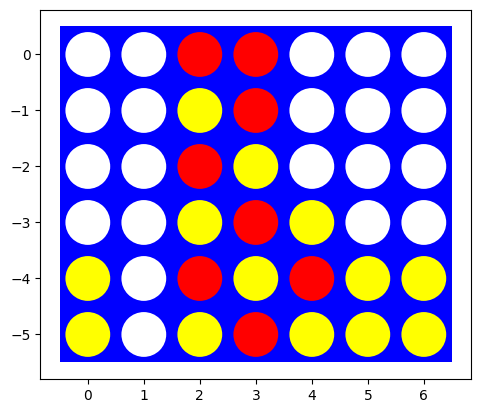

[(1, ('drop', 3)), (-1, ('drop', 3)), (1, ('drop', 3)), (-1, ('drop', 3)), (1, ('drop', 3)), (-1, ('drop', 2)), (1, ('drop', 2)), (-1, ('drop', 2)), (1, ('drop', 2)), (-1, ('drop', 2)), (1, ('drop', 3)), (-1, ('drop', 0)), (1, ('drop', 2)), (-1, ('drop', 1)), (1, ('move', 1, 6)), (-1, ('drop', 1)), (1, ('move', 1, 0)), (-1, ('drop', 1)), (1, ('move', 1, 6)), (-1, ('drop', 1)), (1, ('move', 1, 5)), (-1, ('drop', 4)), (1, ('move', 4, 5)), (-1, ('drop', 4)), (1, ('drop', 4)), (-1, ('drop', 4))]


In [19]:
def heuristic_agent(depth):
    def agent(board, player=1):
        return alpha_beta_search(board, player, depth=depth, heuristic=heuristic,
                                 order=WIN_FIRST)["move"]
    return agent


random.seed(3)
start = time.perf_counter()
res, games = play(heuristic_agent(2), heuristic_agent(4), N=1, verbose=True)
print(f"depth 2 (red) vs depth 4 (yellow): {res}, {len(games[0])} plies, "
      f"{time.perf_counter() - start:.1f} s")

final = new_board()
for player, action in games[0]:
    final = result(final, player, action)
visualize(final)
print(games[0])


**Hai agent heuristic đấu nhau (6×7, connect 4, không random)**

Kết quả: **vàng (depth 4) thắng đỏ (depth 2) sau 26 ply**, tổng thời gian ~1.0 s.

* Tìm kiếm sâu hơn thắng — phù hợp kỳ vọng: depth 2 chỉ thấy "mình đi + đối thủ đáp", không thấy kế hoạch 2 nước.
* Danh sách nước đi cho thấy luật mean bị dùng rất nhiều ở nửa sau ván: đỏ liên tục `move 1→6`, `move 1→0`, `move 4→5`… Đó là dấu hiệu **hoán đổi quân vô ích** — khi không tìm được nước thắng, agent dùng nước mean để "câu giờ", và vì không có tri thức về lặp lại ở độ sâu giới hạn, nó không nhận ra mình đang đi vòng.
* Bài học: với luật mean, chỉ cần thêm một heuristic phạt việc lặp lại (hoặc cộng điểm cho việc giữ quân đáy của đối thủ bị chôn) là chất lượng chơi tăng rõ.


## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [20]:
def random_playout(board, player, pieces, max_plies=200):
    """random moves until somebody wins (0 if the ply limit is reached)"""
    pl = player
    for _ in range(max_plies):
        board, changed, pieces = apply_action(board, pl, random.choice(actions(board, pl)), pieces)
        winner = winner_of(board, changed, pieces, board.size)
        if winner is not None:
            return winner
        pl = -pl
    return 0


def monte_carlo_player(board, player=1, N=200):
    """pure Monte Carlo: every action is tried in N random games, keep the best win rate"""
    pieces = int(np.count_nonzero(board))
    best, best_score, scores = None, -1.0, {}
    for a in actions(board, player):
        wins = 0
        for _ in range(N):
            child, changed, p = apply_action(board, player, a, pieces)
            winner = winner_of(child, changed, p, child.size)
            if winner is not None:              # the action ends the game right away
                wins += winner == player
            else:
                wins += random_playout(child, -player, p) == player
        scores[a] = wins / N
        if scores[a] > best_score:
            best, best_score = a, scores[a]
    return best, scores


random.seed(2)
with connect_rule(3):
    for name, (board, player) in test_boards.items():
        start = time.perf_counter()
        move, scores = monte_carlo_player(board, player, N=200)
        print(f"{name:<38} move = {str(move):<14} time = {time.perf_counter() - start:.2f} s")
        print("   win rates:", {f"{a[0]} {a[1]}" + (f"->{a[2]}" if a[0] == "move" else ""): round(v, 2)
                                for a, v in scores.items()})

random.seed(3)
start = time.perf_counter()
res = play(lambda b, p: monte_carlo_player(b, p, N=50)[0], random_player, N=10, board=new_board())
print(f"\npure Monte Carlo (red) vs random (yellow), 6x7: {res}, "
      f"{time.perf_counter() - start:.1f} s")


B1: red wins with one drop             move = ('drop', 2)    time = 0.06 s
   win rates: {'drop 0': 0.44, 'drop 1': 0.46, 'drop 2': 1.0, 'drop 3': 0.5, 'move 3->0': 0.33, 'move 3->1': 0.24, 'move 3->2': 0.11}


B2: red must block yellow              move = ('drop', 1)    time = 0.11 s
   win rates: {'drop 0': 0.7, 'drop 1': 0.91, 'drop 2': 0.78, 'drop 3': 0.73, 'move 2->0': 0.75, 'move 2->1': 0.71, 'move 2->3': 0.79, 'move 3->0': 0.81, 'move 3->1': 0.77, 'move 3->2': 0.83}


B3: red wins with a mean move          move = ('move', 0, 1) time = 0.07 s
   win rates: {'drop 0': 0.9, 'drop 1': 0.92, 'drop 2': 0.91, 'drop 3': 0.94, 'move 0->1': 1.0, 'move 0->2': 1.0, 'move 0->3': 1.0, 'move 3->0': 0.81, 'move 3->1': 0.82, 'move 3->2': 0.78}


B4: B1 with yellow to move             move = ('drop', 2)    time = 0.11 s
   win rates: {'drop 0': 0.7, 'drop 1': 0.74, 'drop 2': 0.94, 'drop 3': 0.76, 'move 0->1': 0.8, 'move 0->2': 0.69, 'move 0->3': 0.76, 'move 1->0': 0.77, 'move 1->2': 0.7, 'move 1->3': 0.77}


B5: quiet board, no tactic             move = ('drop', 3)    time = 0.11 s
   win rates: {'drop 0': 0.73, 'drop 1': 0.76, 'drop 2': 0.75, 'drop 3': 0.77, 'move 2->0': 0.47, 'move 2->1': 0.36, 'move 2->3': 0.39}



pure Monte Carlo (red) vs random (yellow), 6x7: {1: 10, -1: 0, 0: 0}, 9.8 s


**Pure Monte Carlo Search**

Cách làm: với **mỗi** nước đi hợp lệ ở gốc, chơi $N$ ván ngẫu nhiên hoàn toàn từ thế cờ sau nước đó, chọn nước có tỉ lệ thắng cao nhất. Không có heuristic, không có cắt tỉa — chỉ có thống kê.

| Thế cờ | Nước MC chọn | Tỉ lệ thắng | Exact |
|---|---|---|---|
| B1 | drop 2 | **1.00** | drop 2 |
| B2 | drop 1 | 0.91 | drop 1 |
| B3 | move 0→1 | **1.00** | move 0→1 |
| B4 (`player=-1`) | drop 2 | 0.94 | drop 2 |
| B5 | drop 3 | 0.77 | drop 0 |

* Nước thắng ngay luôn đạt 1.00, và nước **mean** thắng ở B3 cũng đạt 1.00 — MC nhận ra tactic ngắn mà không cần tri thức nào về luật mean.
* B5: MC chọn `drop 3` (giữa) trong khi exact chọn `drop 0`; tỉ lệ 0.77 so với 0.73 của `drop 0` chỉ là **nhiễu thống kê** với 200 rollout, không phải MC "giỏi hơn".
* MC (N=50, đỏ) thắng random 10–0 trên 6×7 trong 9.7 s → khoảng 0.05 s/nước. Rẻ hơn nhiều so với tìm kiếm đầy đủ, nhưng chất lượng phụ thuộc mạnh vào $N$ và vào việc đối thủ chơi ngẫu nhiên.


### Best First Move

How would you determine what the best first move for a standard board ($6 \times 7$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

column 0: win rate 0.758 +- 0.008


column 1: win rate 0.761 +- 0.009


column 2: win rate 0.765 +- 0.005


column 3: win rate 0.768 +- 0.012


column 4: win rate 0.767 +- 0.011


column 5: win rate 0.764 +- 0.013


column 6: win rate 0.760 +- 0.010


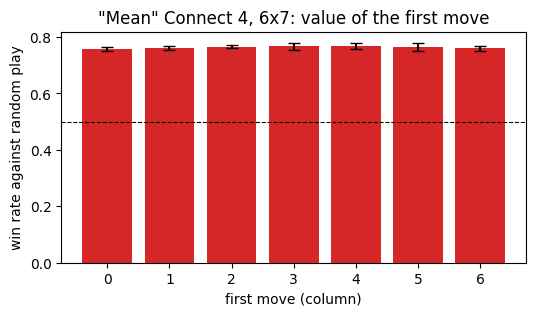

the depth-4 heuristic agent also chooses ('drop', 3) (value -0.20)


In [21]:
import matplotlib.pyplot as plt

random.seed(5)
columns = list(range(7))
means, stds = [], []
for col in columns:
    rates = []
    for _ in range(5):                       # 5 independent blocks of 2000 playouts
        board, _, pieces = apply_action(new_board(), 1, drop(col), 0)
        wins = sum(random_playout(board, -1, pieces) == 1 for _ in range(2000))
        rates.append(wins / 2000)
    means.append(float(np.mean(rates)))
    stds.append(float(np.std(rates)))
    print(f"column {col}: win rate {means[-1]:.3f} +- {stds[-1]:.3f}")

plt.figure(figsize=(6, 3))
plt.bar(columns, means, yerr=stds, capsize=4, color="tab:red")
plt.axhline(0.5, color="black", lw=0.8, ls="--")
plt.xlabel("first move (column)")
plt.ylabel("win rate against random play")
plt.title('"Mean" Connect 4, 6x7: value of the first move')
plt.show()

best = alpha_beta_search(new_board(), 1, depth=4, heuristic=heuristic, order=WIN_FIRST)
print(f"the depth-4 heuristic agent also chooses {best['move']} (value {best['value']:+.2f})")


**Nước đi đầu tiên tốt nhất trên bàn chuẩn 6×7**

Bảng tỉ lệ thắng của từng nước thả đầu tiên (mỗi cột: 5 lần × 2 000 ván ngẫu nhiên):

| Cột | 0 | 1 | 2 | 3 (giữa) | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| Tỉ lệ thắng | 0.758 | 0.761 | 0.765 | **0.768** | 0.767 | 0.764 | 0.760 |
| Độ lệch chuẩn | 0.008 | 0.009 | 0.005 | 0.012 | 0.011 | 0.013 | 0.010 |

* Cột giữa (3) có trung bình cao nhất, nhưng **chênh lệch 0.010 nhỏ hơn cả độ lệch chuẩn 0.012** → về mặt thống kê, 7 nước đầu **không khác nhau rõ rệt**.
* Nguyên nhân: đấu với random thì lợi thế đi trước (~76%) lấn át hoàn toàn lợi thế cột. Muốn phân biệt được các cột cần đối thủ mạnh hơn (heuristic agent) và số ván lớn hơn nhiều — hướng mở rộng, không làm trong bài này.
* Tuy vậy, agent heuristic depth 4 (tất định) cũng chọn `drop 3` với value −0.20. Hai phương pháp độc lập cùng chỉ về cột giữa, nên có thể tạm kết luận: **nước đầu tốt nhất là thả cột giữa (cột 3)** — giống Connect 4 thường, nhưng mức lợi thế nhỏ hơn nhiều vì luật mean cho phép đối thủ phá cột đó.
* Cách tổng quát để tìm nước đầu tốt nhất: (1) dùng MC với $N$ đủ lớn, (2) dùng search sâu trên bàn nhỏ rồi suy ra, hoặc (3) giải hẳn trò chơi bằng retrograde analysis / alpha-beta có transposition table (không làm ở đây vì 6×7 quá lớn).


## Tổng kết

**Những gì đã làm**

* Định nghĩa đầy đủ search problem cho "Mean" Connect 4 và cài đặt environment hoạt động với **mọi kích thước bàn**: `actions`, `result`, `terminal`, `utility`, agent random, vòng lặp `play`.
* Minimax + alpha-beta với **luật lặp lại = hòa**, phát hiện thắng tăng dần theo ô thay đổi, đếm node/cutoff, giới hạn thời gian.
* Ba chiến lược move ordering và đo ảnh hưởng: nhanh hơn **13–52 lần** trên bàn trống 4×4.
* Heuristic đánh giá trong $(-1, 1)$ và alpha-beta cắt độ sâu, đo trade-off giữa depth và thời gian trên bàn 6×7.
* Pure Monte Carlo search, đánh giá trên các thế cờ thủ công và dùng để trả lời câu hỏi "nước đầu tốt nhất".

**Hạn chế đã biết**

* Luật mean khiến ván cờ có thể lặp vô hạn. Bài này xử lý bằng (a) luật lặp = hòa trong search và (b) giới hạn `max_plies` trong `play` (quá giới hạn tính là hòa). Một luật chính thức (ví dụ 3 lần lặp = hòa) sẽ chặt chẽ hơn.
* Không có transposition table: rất nhiều thế cờ đạt được bằng nhiều thứ tự nước khác nhau (đặc biệt vì nước mean), nên bảng băm sẽ giảm mạnh số node — đây là cải tiến lớn nhất còn để ngỏ.
* Alpha-beta chỉ dùng heuristic "tĩnh"; agent cắt độ sâu vẫn bỏ sót tactic sâu hơn depth (ví dụ B5).
* Khi value bằng nhau, agent chọn nước gặp đầu tiên theo move ordering; vì vậy nó có thể chọn nước thắng chậm thay vì nước thắng ngay nếu ordering không ưu tiên nước thắng.
* Thí nghiệm "nước đầu tốt nhất" bị giới hạn bởi đối thủ random; kết luận về cột giữa nên đọc như một quan sát, không phải kết quả đã chứng minh.
